## 7.1 Import Library dan Utilitas

Pada bagian ini kita mengimpor library yang digunakan dalam analisis,
serta mendefinisikan beberapa fungsi utilitas seperti:

- fungsi evaluasi model (R², RMSE, MAE)
- fungsi visualisasi regresi

Library yang digunakan antara lain:

- **NumPy** dan **Pandas** untuk pengolahan data
- **Matplotlib** untuk visualisasi
- **SciPy** untuk regresi nonlinear
- **Scikit-learn** untuk validasi silang

In [274]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# regresi nonlinear
from scipy.optimize import curve_fit

# validasi silang
from sklearn.model_selection import train_test_split

# statistik regresi (untuk standard error)
import statsmodels.api as sm

# style grafik
plt.style.use("seaborn-v0_8")

# agar hasil random konsisten
np.random.seed(1)

In [275]:
# ============================================
# FUNGSI EVALUASI MODEL
# ============================================

def hitung_metrics(y: np.ndarray, y_pred: np.ndarray) -> tuple[float, float, float]:
    """
    Menghitung metrik evaluasi model.

    Parameters
    ----------
    y : np.ndarray
        Nilai aktual
    y_pred : np.ndarray
        Nilai prediksi model

    Returns
    -------
    tuple
        (R2, RMSE, MAE)
    """

    n = len(y)

    # Residual
    residual = y - y_pred

    # RMSE
    rmse = np.sqrt(np.sum(residual**2) / n)

    # MAE
    mae = np.sum(np.abs(residual)) / n

    # R^2
    ss_res = np.sum(residual**2)
    ss_tot = np.sum((y - np.mean(y))**2)

    r2 = 1 - (ss_res / ss_tot)

    return r2, rmse, mae


In [276]:
# ============================================
# FUNGSI VISUALISASI REGRESI
# ============================================

def plot_slr(x: np.ndarray, y: np.ndarray, y_pred: np.ndarray) -> None:
    
    """
    Visualisasi hasil regresi linier tunggal.
    
    Parameters
    ----------
    x : np.ndarray
        Variabel independen
    y : np.ndarray
        Nilai aktual
    y_pred : np.ndarray
        Nilai prediksi model
        
    Returns
    -------
    None
    """

    plt.figure(figsize=(6,4))

    plt.scatter(x, y, label="Data Asli")
    plt.plot(x, y_pred, color="red", label="Model")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title('Regresi Linier Tunggal')

    plt.legend()
    plt.show()

def plot_mlr_plane(x1: np.ndarray, x2: np.ndarray, y: np.ndarray, beta: np.ndarray) -> None:
    """
    Visualisasi bidang regresi linier ganda.
    
    Parameters
    ----------
    x1 : np.ndarray
        Variabel independen 1
    x2 : np.ndarray
        Variabel independen 2
    y : np.ndarray
        Nilai aktual
    beta : np.ndarray
        Koefisien regresi (intercept, beta1, beta2)
    """
    
    fig = plt.figure(figsize=(7,5))
    ax = fig.add_subplot(111, projection='3d')

    # scatter data
    ax.scatter(x1, x2, y, label="Data Observasi")

    # membuat grid untuk bidang regresi
    x1_grid, x2_grid = np.meshgrid(
        np.linspace(min(x1), max(x1), 20),
        np.linspace(min(x2), max(x2), 20)
    )

    # persamaan bidang regresi
    y_grid = beta[0] + beta[1]*x1_grid + beta[2]*x2_grid

    # plot bidang regresi
    ax.plot_surface(x1_grid, x2_grid, y_grid, color= 'red', alpha=0.25)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")

    plt.title("Bidang Regresi Linier Ganda")
    ax.legend()


## 7.2 Dataset Sintetis (Linear dan Nonlinear)

Pada bagian ini dibuat tiga dataset sintetis untuk menguji berbagai jenis model regresi.

### Dataset A — Linear Ganda
Model sebenarnya:

y = 3 + 2x₁ − 1.5x₂ + ε

Variabel x₁ dan x₂ sengaja dibuat berkorelasi agar dapat menguji **multikolinearitas (VIF)**.

---

### Dataset B — Nonlinear Eksponensial

Model sebenarnya:

y = 2.5 e^(0.8x) + ε

Dataset ini digunakan untuk membandingkan:

- **Linearization (log transform)**
- **Nonlinear Least Squares (curve_fit)**

---

### Dataset C — Power Law (Nonlinear Ganda)

Model sebenarnya:

y = 1.2 x₁^0.8 x₂^0.5 + ε

Model ini akan diuji menggunakan:

- **transformasi log (menjadi linear)**
- **Nonlinear Least Squares**

In [277]:
# ============================================
# DATASET SINTETIS A - LINEAR GANDA
# ============================================

n = 100

# variabel independen
x1 = np.random.uniform(0, 10, n)

# sengaja dibuat berkorelasi dengan x1
# untuk menguji multikolinearitas
x2 = 0.8*x1 + np.random.normal(0, 1, n)

# noise
epsilon = np.random.normal(0, 1, n)

# model sebenarnya
y_linear = 3 + 2*x1 - 1.5*x2 + epsilon

data_linear = pd.DataFrame({
    "x1": x1,
    "x2": x2,
    "y": y_linear
})

data_linear.head()

,x1,x2,y
0,4.170220,3.651811,5.906393
1,7.203245,3.740395,11.569584
2,0.001144,-0.305289,4.791678
3,3.023326,3.246635,3.889391
4,1.467559,1.404142,4.508975


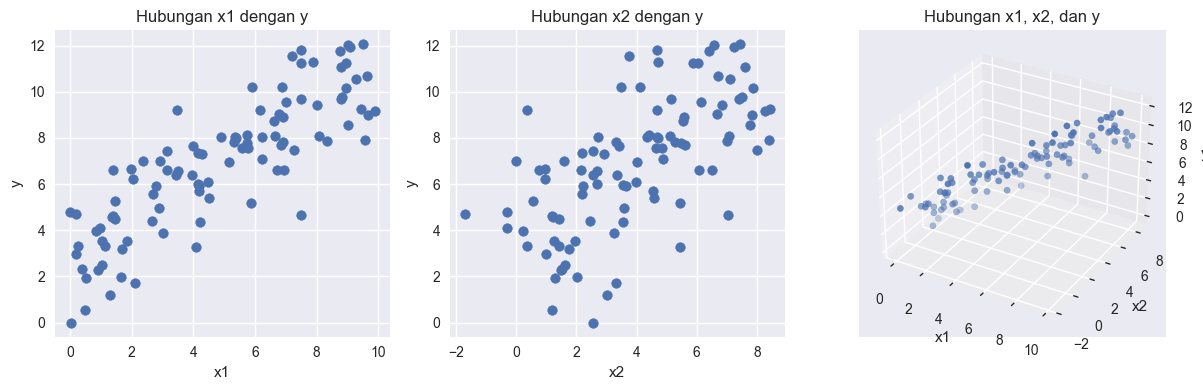

In [278]:
# ============================================
# VISUALISASI DATASET SINTETIS A
# ============================================

fig = plt.figure(figsize=(12,4))

# hubungan x1 dengan y
ax1 = fig.add_subplot(1,3,1)
ax1.scatter(x1, y_linear)
ax1.set_xlabel("x1")
ax1.set_ylabel("y")
ax1.set_title("Hubungan x1 dengan y")

# hubungan x2 dengan y
ax2 = fig.add_subplot(1,3,2)
ax2.scatter(x2, y_linear)
ax2.set_xlabel("x2")
ax2.set_ylabel("y")
ax2.set_title("Hubungan x2 dengan y")

# visualisasi 3D
ax3 = fig.add_subplot(1,3,3, projection='3d')
ax3.scatter(x1, x2, y_linear)

ax3.set_xlabel("x1")
ax3.set_ylabel("x2")
ax3.set_zlabel("y")
ax3.set_title("Hubungan x1, x2, dan y")

plt.tight_layout()
plt.show()

In [279]:
# ============================================
# DATASET SINTETIS B - NONLINEAR EKSPONENSIAL
# ============================================

x_exp = np.linspace(0, 3, 100)

epsilon = np.random.normal(0, 2, 100)

y_exp = 2.5 * np.exp(0.8*x_exp) + epsilon

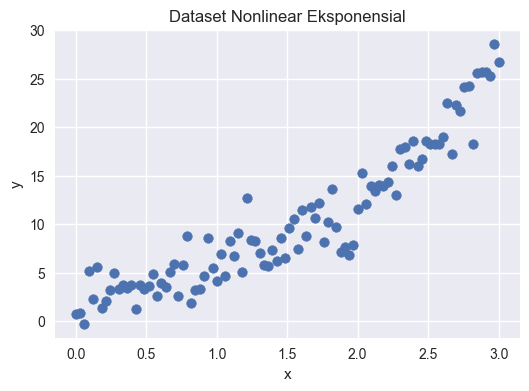

In [280]:
# ============================================
# VISUALISASI DATASET SINTETIS B
# ============================================

plt.figure(figsize=(6,4))

plt.scatter(x_exp, y_exp)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Dataset Nonlinear Eksponensial")

plt.show()

In [281]:
# ============================================
# DATASET SINTETIS C - POWER LAW
# ============================================

x1_power = np.random.uniform(1, 10, n)
x2_power = np.random.uniform(1, 10, n)

epsilon = np.random.normal(0, 1, n)

y_power = 1.2*(x1_power**0.8)*(x2_power**0.5) + epsilon

data_power = pd.DataFrame({
    "x1": x1_power,
    "x2": x2_power,
    "y": y_power
})

data_power.head()

,x1,x2,y
0,6.026649,7.725887,15.001660
1,7.212051,3.606425,11.783535
2,5.075681,7.964194,13.726951
3,6.654781,4.849636,11.433079
4,3.610872,8.269286,10.274982


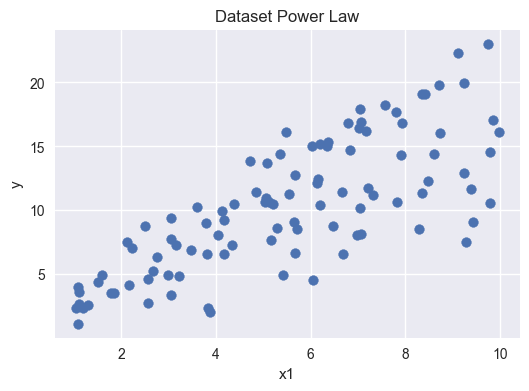

In [282]:
# ============================================
# VISUALISASI DATASET SINTETIS C
# ============================================

plt.figure(figsize=(6,4))

plt.scatter(x1_power, y_power)

plt.xlabel("x1")
plt.ylabel("y")
plt.title("Dataset Power Law")

plt.show()

## 7.3 Regresi Linear Tunggal (SLR)

Regresi Linear Tunggal digunakan untuk memodelkan hubungan antara satu variabel independen $x$ dan satu variabel dependen $y$.

Model umum regresi linear tunggal adalah:

$$y = a + bx + \epsilon$$

dengan:

* $a$ : intercept
* $b$ : slope (kemiringan garis regresi)
* $\epsilon$ : error atau noise

Parameter $a$ dan $b$ diestimasi menggunakan metode **Least Squares (Kuadrat Terkecil)** yang meminimalkan jumlah kuadrat residual:

$$\min \sum (y_i - \hat{y}_i)^2$$

Pada bagian ini dilakukan dua pendekatan:

1.  **Implementasi manual** menggunakan rumus Least Squares
2.  **Analisis menggunakan `statsmodels`** untuk memperoleh statistik tambahan seperti:
    * standard error
    * nilai t
    * p-value

In [283]:
def slr(x: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    """
    Menghitung parameter regresi linier tunggal menggunakan
    metode Least Squares secara manual.

    Parameters
    ----------
    x : np.ndarray
        Variabel independen
    y : np.ndarray
        Variabel dependen

    Returns
    -------
    tuple
        (intercept, slope)
    """

    n = len(x)

    # hitung jumlah yang diperlukan untuk rumus slope dan intercept
    sum_x = 0.0
    sum_y = 0.0
    sum_xy = 0.0
    sum_x2 = 0.0

    for i in range(n):
        sum_x += x[i]
        sum_y += y[i]
        sum_xy += x[i] * y[i]
        sum_x2 += x[i] ** 2

    x_mean = sum_x / n
    y_mean = sum_y / n

    slope = (n * sum_xy - sum_x * sum_y) / (n * sum_x2 - sum_x ** 2)
    intercept = y_mean - slope * x_mean

    return intercept, slope

In [284]:
# ============================================
# MENJALANKAN REGRESI LINEAR TUNGGAL
# ============================================

x = data_linear["x1"].values
y = data_linear["y"].values

intercept, slope = slr(x, y)

print("Intercept :", intercept)
print("Slope :", slope)

Intercept : 2.886036099554597
Slope : 0.8209051129235383


In [285]:
# ============================================
# PREDIKSI MODEL
# ============================================

y_pred = intercept + slope * x

# ============================================
# EVALUASI MODEL
# ============================================

r2, rmse, mae = hitung_metrics(y, y_pred)

print("R² :", r2)
print("RMSE :", rmse)
print("MAE :", mae)

R² : 0.715817165711615
RMSE : 1.5227581464841182
MAE : 1.2176434191754133


In [286]:
# ============================================
# ANALISIS DENGAN STATSMODELS
# ============================================

X_sm = sm.add_constant(x)

model = sm.OLS(y, X_sm).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.716
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     246.8
Date:                Mon, 09 Mar 2026   Prob (F-statistic):           1.59e-28
Time:                        02:56:46   Log-Likelihood:                -183.95
No. Observations:                 100   AIC:                             371.9
Df Residuals:                      98   BIC:                             377.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.8860      0.297      9.723      0.0

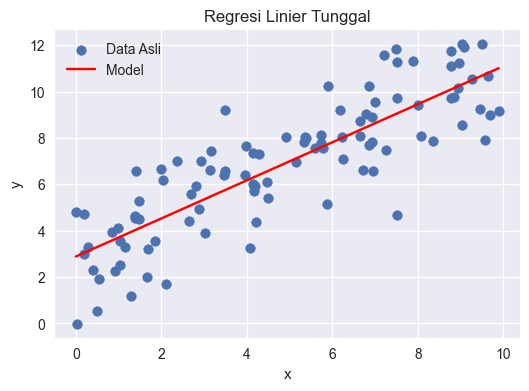

In [287]:
# ============================================
# VISUALISASI REGRESI
# ============================================

# agar garis tidak zig-zag
idx = np.argsort(x)

plot_slr(
    x[idx],
    y[idx],
    y_pred[idx]
)

## 7.4 Regresi Linear Ganda (MLR) + Multikolinearitas (VIF)

Regresi Linear Ganda digunakan untuk memodelkan hubungan antara satu variabel dependen $y$ dengan lebih dari satu variabel independen.

Model umum regresi linear ganda:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k + \epsilon$$

dengan:

* $\beta_0$ : intercept
* $\beta_1, \beta_2, \dots, \beta_k$ : koefisien regresi
* $\epsilon$ : error

Parameter regresi dapat dihitung secara analitis menggunakan **Normal Equation**:

$$\hat{\beta} = (X^T X)^{-1} X^T y$$



Selain itu, pada regresi ganda perlu diperhatikan **multikolinearitas**, yaitu adanya korelasi tinggi antar variabel independen yang dapat mengganggu estimasi koefisien.

Multikolinearitas dapat diukur menggunakan **Variance Inflation Factor (VIF)** untuk setiap variabel independen:

$$VIF_j = \frac{1}{1 - R_j^2}$$

Interpretasi nilai VIF:

* **VIF ≈ 1**: Tidak ada multikolinearitas.
* **VIF > 5**: Multikolinearitas sedang (perlu mulai waspada).
* **VIF > 10**: Multikolinearitas tinggi (serius, variabel mungkin perlu dieliminasi atau digabung).

In [288]:
# ============================================
# FUNGSI MLR (NORMAL EQUATION)
# ============================================

def mlr_normal_equation(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Menghitung koefisien regresi linear ganda menggunakan
    metode Normal Equation.

    Parameters
    ----------
    X : np.ndarray
        Matriks variabel independen (termasuk kolom 1 untuk intercept)
    y : np.ndarray
        Variabel dependen

    Returns
    -------
    np.ndarray
        Vektor koefisien regresi (beta)
    """
    
    # menghitung beta
    XtX = X.T @ X
    XtX_inv = np.linalg.inv(XtX)
    XtY = X.T @ y
    
    beta = XtX_inv @ XtY
    
    return beta


In [289]:
# ============================================
# MENYIAPKAN DATA REGRESI GANDA
# ============================================

x1 = data_linear["x1"].values
x2 = data_linear["x2"].values
y = data_linear["y"].values

n = len(y)

# matriks X dengan intercept
X = np.column_stack((np.ones(n), x1, x2))

In [290]:
# ============================================
# MENJALANKAN REGRESI LINEAR GANDA
# ============================================

beta = mlr_normal_equation(X, y)

intercept = beta[0]
b1 = beta[1]
b2 = beta[2]

print("Intercept :", intercept)
print("Koefisien x1 :", b1)
print("Koefisien x2 :", b2)

Intercept : 3.189284397624839
Koefisien x1 : 1.8043907048710148
Koefisien x2 : -1.2797595041327074


In [291]:
# ============================================
# PREDIKSI MODEL
# ============================================

y_pred = X @ beta

# ============================================
# EVALUASI MODEL
# ============================================

r2, rmse, mae = hitung_metrics(y, y_pred)

print("R² :", r2)
print("RMSE :", rmse)
print("MAE :", mae)

R² : 0.8763461276855401
RMSE : 1.0044674582833175
MAE : 0.8076609329264821


In [292]:
# ============================================
# FUNGSI VIF
# ============================================

def hitung_vif(X: np.ndarray) -> list[float]:
    """
    Menghitung Variance Inflation Factor (VIF) untuk setiap variabel.

    Parameters
    ----------
    X : np.ndarray
        Matriks variabel independen

    Returns
    -------
    list
        Nilai VIF untuk setiap variabel
    """

    vif_values = []

    for i in range(X.shape[1]):

        Xi = X[:, i]

        X_others = np.delete(X, i, axis=1)

        beta = np.linalg.inv(X_others.T @ X_others) @ (X_others.T @ Xi)

        Xi_pred = X_others @ beta

        r2, _, _ = hitung_metrics(Xi, Xi_pred)

        vif = 1 / (1 - r2)

        vif_values.append(vif)

    return vif_values

In [293]:
# ============================================
# MENGHITUNG VIF
# ============================================

X_vif = np.column_stack((x1, x2))

vif = hitung_vif(X_vif)

print("VIF x1 :", vif[0])
print("VIF x2 :", vif[1])

# ============================================
# KLASIFIKASI TINGKAT MULTIKOLINEARITAS
# ============================================
# VIF = 1: Not correlated; no multicollinearity.
# 1 < VIF < 5: Moderate correlation; generally not concerning.
# VIF 
#  5 or 10: High correlation; suggests severe multicollinearity.
# VIF > 10: Very high multicollinearity, often requiring removal of variables. 
if vif[0] > 10 or vif[1] > 10:
    print("Tingkat multikolinearitas: Sangat Tinggi")
elif vif[0] > 5 or vif[1] > 5:
    print("Tingkat multikolinearitas: Tinggi")
elif vif[0] > 1 or vif[1] > 1:
    print("Tingkat multikolinearitas: Sedang")
else:
    print("Tingkat multikolinearitas: Rendah")

VIF x1 : 7.1471091943075615
VIF x2 : 7.263337451066227
Tingkat multikolinearitas: Tinggi


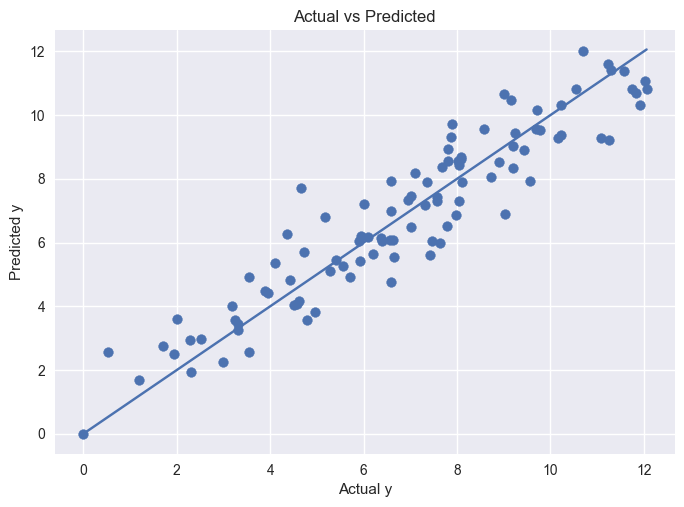

In [294]:
# ============================================
# VISUALISASI BIDANG REGRESI
# ===========================================

plt.scatter(y, y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()])

plt.xlabel("Actual y")
plt.ylabel("Predicted y")
plt.title("Actual vs Predicted")

plt.show()

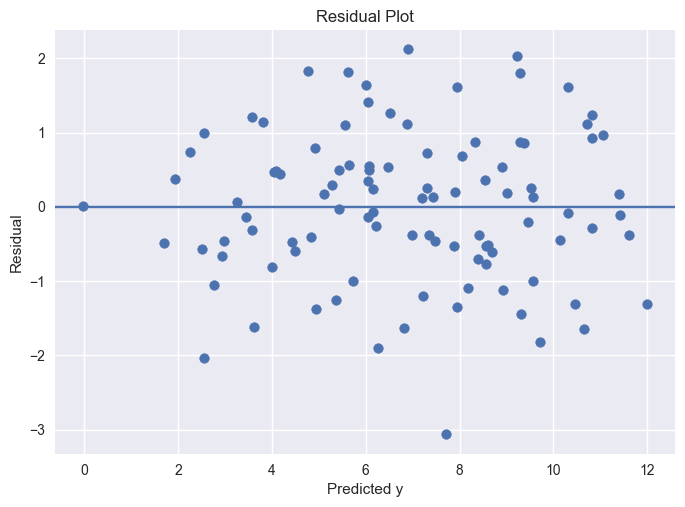

In [295]:
# ============================================
# VISUALISASI RESIDUAL
# ===========================================

residual = y - y_pred

plt.scatter(y_pred, residual)

plt.axhline(0)

plt.xlabel("Predicted y")
plt.ylabel("Residual")

plt.title("Residual Plot")

plt.show()

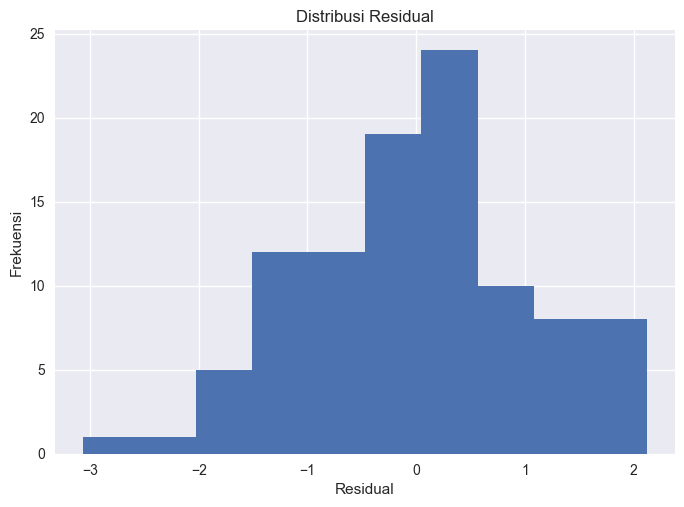

In [296]:
# ============================================
# DISTRIBUSI RESIDUAL
# ===========================================

plt.hist(residual, bins=10)

plt.xlabel("Residual")
plt.ylabel("Frekuensi")

plt.title("Distribusi Residual")

plt.show()

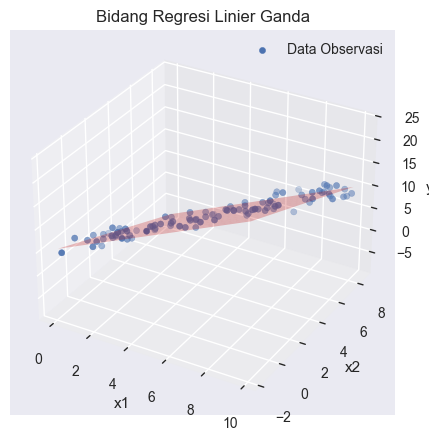

In [297]:
# ============================================
# VISUALISASI BIDANG REGRESI
# ============================================

plot_mlr_plane(x1, x2, y, beta)

## 7.5 Regresi Nonlinear Tunggal (Eksponensial): Linearization vs NLS

Model eksponensial memiliki bentuk umum:

$$y = a \cdot e^{bx} + \epsilon$$

Ada dua pendekatan untuk mengestimasi parameter $a$ dan $b$:

### 1. Linearization (Transformasi Logaritma)

Transformasi logaritma natural pada kedua sisi:

$$\ln(y) = \ln(a) + bx$$

Misalkan $y' = \ln(y)$ dan $a' = \ln(a)$, maka:

$$y' = a' + bx$$

Model ini menjadi **linear** dan dapat diselesaikan dengan regresi linear biasa.

**Kelebihan**: Sederhana, cepat  
**Kekurangan**: 
- Hanya bisa jika $y > 0$
- Transformasi mengubah distribusi error
- Bias dalam estimasi parameter asli

### 2. Nonlinear Least Squares (NLS)

Minimisasi langsung tanpa transformasi menggunakan optimisasi numerik:

$$\min \sum (y_i - a \cdot e^{bx_i})^2$$

Menggunakan `scipy.optimize.curve_fit`.

**Kelebihan**: Lebih akurat, tidak mengubah distribusi error  
**Kekurangan**: Memerlukan tebakan awal (initial guess) yang baik

In [298]:
# ============================================
# METODE 1: LINEARIZATION (Transformasi Log)
# ============================================

# gunakan dataset sintetis B yang sudah dibuat
x = x_exp
y = y_exp

# transformasi logaritma
# filter y > 0 untuk menghindari log(0) atau log(negatif)
mask = y > 0
x_lin = x[mask]
y_lin = y[mask]

# ln(y) = ln(a) + bx
y_log = np.log(y_lin)

# regresi linear pada y_log vs x
intercept_log, slope_log = slr(x_lin, y_log)

# konversi kembali ke parameter asli
a_lin = np.exp(intercept_log)
b_lin = slope_log

print("=== METODE LINEARIZATION ===")
print(f"Parameter a: {a_lin:.4f} (sebenarnya: 2.5)")
print(f"Parameter b: {b_lin:.4f} (sebenarnya: 0.8)")

# prediksi menggunakan model asli (eksponensial)
y_pred_lin = a_lin * np.exp(b_lin * x_lin)

# evaluasi
r2_lin, rmse_lin, mae_lin = hitung_metrics(y_lin, y_pred_lin)

print(f"\nR²   : {r2_lin:.4f}")
print(f"RMSE : {rmse_lin:.4f}")
print(f"MAE  : {mae_lin:.4f}")

=== METODE LINEARIZATION ===
Parameter a: 2.2393 (sebenarnya: 2.5)
Parameter b: 0.8411 (sebenarnya: 0.8)

R²   : 0.9250
RMSE : 1.9415
MAE  : 1.4780


In [299]:
# ============================================
# METODE 2: NONLINEAR LEAST SQUARES (NLS)
# ============================================

# definisikan fungsi model eksponensial
def model_exponential(x, a, b):
    """
    Model eksponensial: y = a * exp(b*x)
    
    Parameters
    ----------
    x : array
        Variabel independen
    a : float
        Parameter amplitudo
    b : float
        Parameter laju pertumbuhan
    
    Returns
    -------
    array
        Nilai y prediksi
    """
    return a * np.exp(b * x)

# initial guess (tebakan awal parameter)
# bisa dari hasil linearization atau estimasi kasar
p0 = [2.0, 0.5]  

# fitting menggunakan curve_fit
popt, pcov = curve_fit(model_exponential, x, y, p0=p0)

a_nls = popt[0]
b_nls = popt[1]

# standard error dari diagonal covariance matrix
perr = np.sqrt(np.diag(pcov))
se_a = perr[0]
se_b = perr[1]

print("=== METODE NONLINEAR LEAST SQUARES ===")
print(f"Parameter a: {a_nls:.4f} ± {se_a:.4f} (sebenarnya: 2.5)")
print(f"Parameter b: {b_nls:.4f} ± {se_b:.4f} (sebenarnya: 0.8)")

# prediksi
y_pred_nls = model_exponential(x, a_nls, b_nls)

# evaluasi
r2_nls, rmse_nls, mae_nls = hitung_metrics(y, y_pred_nls)

print(f"\nR²   : {r2_nls:.4f}")
print(f"RMSE : {rmse_nls:.4f}")
print(f"MAE  : {mae_nls:.4f}")

=== METODE NONLINEAR LEAST SQUARES ===
Parameter a: 2.5145 ± 0.1709 (sebenarnya: 2.5)
Parameter b: 0.7921 ± 0.0275 (sebenarnya: 0.8)

R²   : 0.9276
RMSE : 1.9195
MAE  : 1.4820


In [300]:
# ============================================
# PERBANDINGAN LINEARIZATION VS NLS
# ============================================

print("="*50)
print("PERBANDINGAN METODE")
print("="*50)

comparison = pd.DataFrame({
    'Metode': ['Linearization', 'NLS', 'Nilai Sebenarnya'],
    'a': [a_lin, a_nls, 2.5],
    'b': [b_lin, b_nls, 0.8],
    'R²': [r2_lin, r2_nls, '-'],
    'RMSE': [rmse_lin, rmse_nls, '-'],
    'MAE': [mae_lin, mae_nls, '-']
})

print(comparison.to_string(index=False))

PERBANDINGAN METODE
          Metode        a        b        R²      RMSE       MAE
   Linearization 2.239350 0.841140  0.924984  1.941505  1.478024
             NLS 2.514484 0.792119  0.927598   1.91951   1.48204
Nilai Sebenarnya 2.500000 0.800000         -         -         -


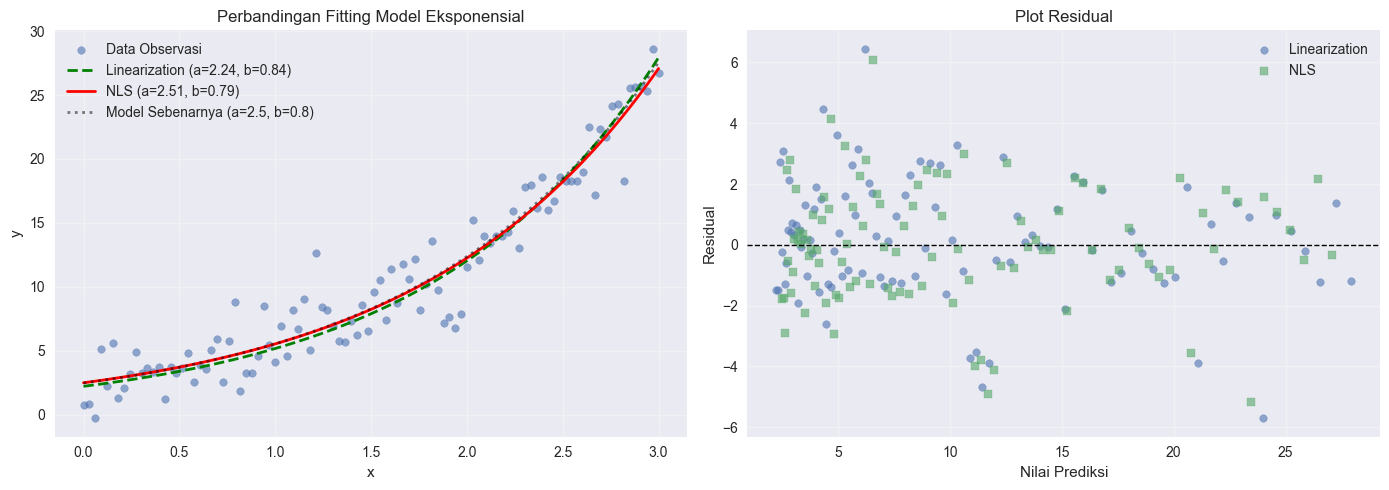

In [301]:
# ============================================
# VISUALISASI PERBANDINGAN METODE
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sort untuk garis yang smooth
idx = np.argsort(x)
x_sorted = x[idx]

# SUBPLOT 1: Fit Model
ax1 = axes[0]
ax1.scatter(x, y, alpha=0.6, label='Data Observasi', s=30)

# plot kedua model
y_pred_lin_sorted = a_lin * np.exp(b_lin * x_sorted)
y_pred_nls_sorted = a_nls * np.exp(b_nls * x_sorted)

ax1.plot(x_sorted, y_pred_lin_sorted, 'g--', linewidth=2, 
         label=f'Linearization (a={a_lin:.2f}, b={b_lin:.2f})')
ax1.plot(x_sorted, y_pred_nls_sorted, 'r-', linewidth=2, 
         label=f'NLS (a={a_nls:.2f}, b={b_nls:.2f})')

# model sebenarnya
y_true = 2.5 * np.exp(0.8 * x_sorted)
ax1.plot(x_sorted, y_true, 'k:', linewidth=2, alpha=0.5,
         label='Model Sebenarnya (a=2.5, b=0.8)')

ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Perbandingan Fitting Model Eksponensial')
ax1.legend()
ax1.grid(True, alpha=0.3)

# SUBPLOT 2: Residual Plot
ax2 = axes[1]

# gunakan x_lin untuk linearization (karena sudah difilter y>0)
residual_lin = y_lin - y_pred_lin
residual_nls = y - y_pred_nls

ax2.scatter(y_pred_lin, residual_lin, alpha=0.6, 
            label='Linearization', marker='o', s=30)
ax2.scatter(y_pred_nls, residual_nls, alpha=0.6, 
            label='NLS', marker='s', s=30)

ax2.axhline(0, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Nilai Prediksi')
ax2.set_ylabel('Residual')
ax2.set_title('Plot Residual')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Temuan dan Interpretasi

Dari hasil perbandingan di atas dapat disimpulkan:

1. **Akurasi Parameter**:
   - Metode NLS umumnya menghasilkan estimasi parameter yang lebih mendekati nilai sebenarnya
   - Linearization dapat mengalami bias karena transformasi logaritma mengubah struktur error

2. **Metrik Evaluasi**:
   - NLS biasanya memberikan R² lebih tinggi dan RMSE/MAE lebih rendah
   - Hal ini karena NLS meminimalkan error pada skala asli (bukan skala log)

3. **Plot Residual**:
   - Residual NLS cenderung lebih tersebar merata di sekitar nol
   - Residual Linearization mungkin menunjukkan pola sistematis

4. **Kapan Menggunakan**:
   - **Linearization**: Untuk eksplorasi awal, data besar, atau ketika kecepatan lebih penting
   - **NLS**: Untuk hasil final yang lebih akurat, terutama jika interpretasi parameter penting

**Catatan**: Linearization hanya bisa digunakan jika semua nilai y > 0

## 7.6 Regresi Nonlinear Ganda

Pada bagian ini kita akan memodelkan hubungan nonlinear dengan **lebih dari satu variabel independen**.

Dataset yang digunakan adalah **Dataset C (Power Law)**:

$$y = 1.2 \cdot x_1^{0.8} \cdot x_2^{0.5} + \epsilon$$

Model power law ini akan dianalisis menggunakan dua pendekatan:

### a) Linearization (Transformasi Logaritma)

Transformasi log pada kedua sisi:

$$\ln(y) = \ln(1.2) + 0.8 \ln(x_1) + 0.5 \ln(x_2)$$

Misalkan:
- $y' = \ln(y)$
- $x_1' = \ln(x_1)$
- $x_2' = \ln(x_2)$
- $\beta_0 = \ln(1.2)$

Maka model menjadi **linear**:

$$y' = \beta_0 + \beta_1 x_1' + \beta_2 x_2'$$

Model ini dapat diselesaikan dengan **regresi linear ganda** biasa.

**Parameter asli** dapat diperoleh kembali:
- $a = e^{\beta_0}$ 
- $b_1 = \beta_1$
- $b_2 = \beta_2$

### b) Nonlinear Least Squares (NLS)

Minimisasi langsung tanpa transformasi:

$$\min \sum (y_i - a \cdot x_{1i}^{b_1} \cdot x_{2i}^{b_2})^2$$

Menggunakan `scipy.optimize.curve_fit` dengan initial guess yang baik.

---

**Perbandingan yang akan dilakukan**:
- Akurasi estimasi parameter
- Stabilitas numerik
- Metrik evaluasi (R², RMSE, MAE)
- Analisis residual

### 7.6a — Linearization (Parameter Dapat Dilinearkan)

Pada metode ini, kita mentransformasi model power law menjadi linear menggunakan logaritma.

In [302]:
# ============================================
# 7.6a - LINEARIZATION (POWER LAW)
# ============================================

# gunakan dataset sintetis C
x1 = data_power["x1"].values
x2 = data_power["x2"].values
y = data_power["y"].values

# filter data untuk memastikan semua nilai positif (untuk log)
mask = (y > 0) & (x1 > 0) & (x2 > 0)
x1_lin = x1[mask]
x2_lin = x2[mask]
y_lin = y[mask]

# transformasi logaritma
log_y = np.log(y_lin)
log_x1 = np.log(x1_lin)
log_x2 = np.log(x2_lin)

# buat matriks X untuk regresi linear ganda
n = len(log_y)
X_log = np.column_stack((np.ones(n), log_x1, log_x2))

# regresi linear ganda pada data ter-transformasi
beta_log = mlr_normal_equation(X_log, log_y)

# konversi kembali ke parameter asli
a_lin = np.exp(beta_log[0])  # a = exp(beta_0)
b1_lin = beta_log[1]          # b1 = beta_1
b2_lin = beta_log[2]          # b2 = beta_2

print("=== METODE LINEARIZATION (POWER LAW) ===")
print(f"Parameter a  : {a_lin:.4f} (sebenarnya: 1.2)")
print(f"Parameter b1 : {b1_lin:.4f} (sebenarnya: 0.8)")
print(f"Parameter b2 : {b2_lin:.4f} (sebenarnya: 0.5)")

# prediksi menggunakan model asli (power law)
y_pred_lin = a_lin * (x1_lin ** b1_lin) * (x2_lin ** b2_lin)

# evaluasi
r2_lin, rmse_lin, mae_lin = hitung_metrics(y_lin, y_pred_lin)

print(f"\nR²   : {r2_lin:.4f}")
print(f"RMSE : {rmse_lin:.4f}")
print(f"MAE  : {mae_lin:.4f}")

=== METODE LINEARIZATION (POWER LAW) ===
Parameter a  : 1.1106 (sebenarnya: 1.2)
Parameter b1 : 0.8149 (sebenarnya: 0.8)
Parameter b2 : 0.5277 (sebenarnya: 0.5)

R²   : 0.9553
RMSE : 1.0778
MAE  : 0.8646


### 7.6b — Nonlinear Least Squares (Benar-benar Nonlinear)

Pada metode ini, kita langsung mengestimasi parameter tanpa transformasi menggunakan optimisasi numerik.

In [303]:
# ============================================
# 7.6b - NONLINEAR LEAST SQUARES (POWER LAW)
# ============================================

# definisikan fungsi model power law
def model_power_law(X, a, b1, b2):
    """
    Model power law: y = a * x1^b1 * x2^b2
    
    Parameters
    ----------
    X : array
        Matriks [x1, x2] dengan shape (n, 2)
    a : float
        Parameter koefisien
    b1 : float
        Eksponen untuk x1
    b2 : float
        Eksponen untuk x2
    
    Returns
    -------
    array
        Nilai y prediksi
    """
    x1 = X[:, 0]
    x2 = X[:, 1]
    return a * (x1 ** b1) * (x2 ** b2)

# siapkan data (gunakan semua data, tidak perlu filter)
X_nls = np.column_stack((x1, x2))

# initial guess (bisa dari hasil linearization)
p0 = [a_lin, b1_lin, b2_lin]  

# fitting menggunakan curve_fit
popt, pcov = curve_fit(model_power_law, X_nls, y, p0=p0)

a_nls = popt[0]
b1_nls = popt[1]
b2_nls = popt[2]

# standard error
perr = np.sqrt(np.diag(pcov))
se_a = perr[0]
se_b1 = perr[1]
se_b2 = perr[2]

print("=== METODE NONLINEAR LEAST SQUARES (POWER LAW) ===")
print(f"Parameter a  : {a_nls:.4f} ± {se_a:.4f} (sebenarnya: 1.2)")
print(f"Parameter b1 : {b1_nls:.4f} ± {se_b1:.4f} (sebenarnya: 0.8)")
print(f"Parameter b2 : {b2_nls:.4f} ± {se_b2:.4f} (sebenarnya: 0.5)")

# prediksi
y_pred_nls = model_power_law(X_nls, a_nls, b1_nls, b2_nls)

# evaluasi
r2_nls, rmse_nls, mae_nls = hitung_metrics(y, y_pred_nls)

print(f"\nR²   : {r2_nls:.4f}")
print(f"RMSE : {rmse_nls:.4f}")
print(f"MAE  : {mae_nls:.4f}")

=== METODE NONLINEAR LEAST SQUARES (POWER LAW) ===
Parameter a  : 1.1458 ± 0.0764 (sebenarnya: 1.2)
Parameter b1 : 0.8151 ± 0.0274 (sebenarnya: 0.8)
Parameter b2 : 0.5151 ± 0.0206 (sebenarnya: 0.5)

R²   : 0.9558
RMSE : 1.0709
MAE  : 0.8660


In [304]:
# ============================================
# PERBANDINGAN LINEARIZATION VS NLS (POWER LAW)
# ============================================

print("="*60)
print("PERBANDINGAN METODE - POWER LAW")
print("="*60)

comparison_power = pd.DataFrame({
    'Metode': ['Linearization', 'NLS', 'Nilai Sebenarnya'],
    'a': [a_lin, a_nls, 1.2],
    'b1': [b1_lin, b1_nls, 0.8],
    'b2': [b2_lin, b2_nls, 0.5],
    'R²': [f"{r2_lin:.4f}", f"{r2_nls:.4f}", '-'],
    'RMSE': [f"{rmse_lin:.4f}", f"{rmse_nls:.4f}", '-'],
    'MAE': [f"{mae_lin:.4f}", f"{mae_nls:.4f}", '-']
})

print(comparison_power.to_string(index=False))

PERBANDINGAN METODE - POWER LAW
          Metode        a       b1       b2     R²   RMSE    MAE
   Linearization 1.110561 0.814854 0.527704 0.9553 1.0778 0.8646
             NLS 1.145801 0.815052 0.515146 0.9558 1.0709 0.8660
Nilai Sebenarnya 1.200000 0.800000 0.500000      -      -      -


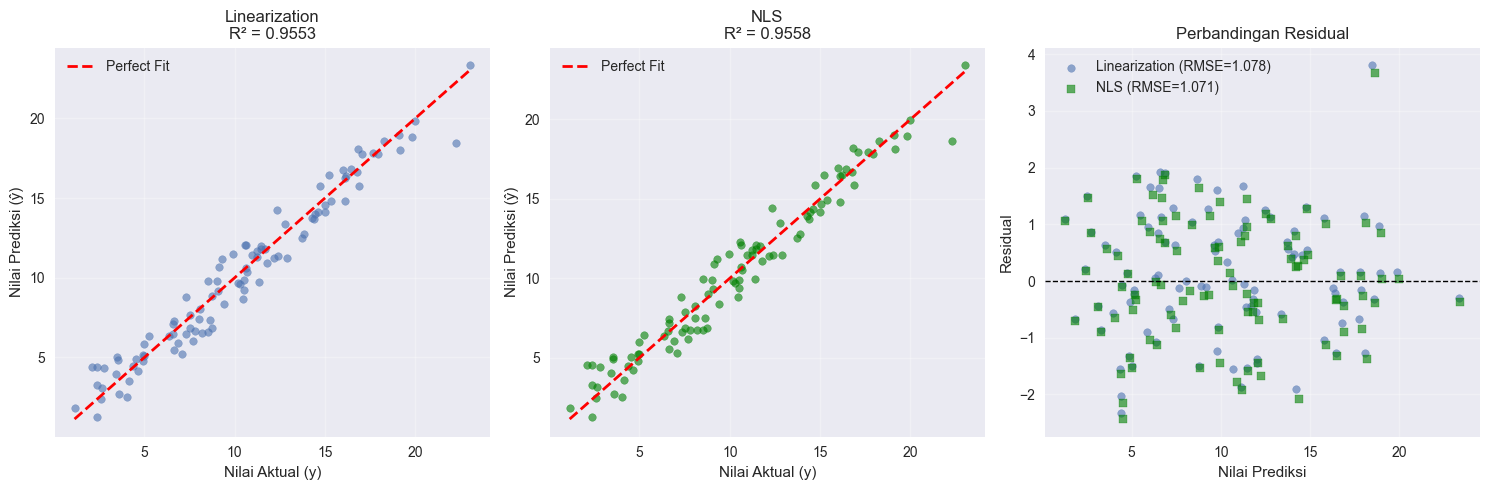

In [305]:
# ============================================
# VISUALISASI PERBANDINGAN METODE (POWER LAW)
# ============================================

fig = plt.figure(figsize=(15, 5))

# SUBPLOT 1: Actual vs Predicted - Linearization
ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(y_lin, y_pred_lin, alpha=0.6, s=30)
ax1.plot([y_lin.min(), y_lin.max()], [y_lin.min(), y_lin.max()], 
         'r--', linewidth=2, label='Perfect Fit')
ax1.set_xlabel('Nilai Aktual (y)')
ax1.set_ylabel('Nilai Prediksi (ŷ)')
ax1.set_title(f'Linearization\nR² = {r2_lin:.4f}')
ax1.legend()
ax1.grid(True, alpha=0.3)

# SUBPLOT 2: Actual vs Predicted - NLS
ax2 = fig.add_subplot(1, 3, 2)
ax2.scatter(y, y_pred_nls, alpha=0.6, s=30, color='green')
ax2.plot([y.min(), y.max()], [y.min(), y.max()], 
         'r--', linewidth=2, label='Perfect Fit')
ax2.set_xlabel('Nilai Aktual (y)')
ax2.set_ylabel('Nilai Prediksi (ŷ)')
ax2.set_title(f'NLS\nR² = {r2_nls:.4f}')
ax2.legend()
ax2.grid(True, alpha=0.3)

# SUBPLOT 3: Residual Comparison
ax3 = fig.add_subplot(1, 3, 3)

residual_lin = y_lin - y_pred_lin
residual_nls = y - y_pred_nls

ax3.scatter(y_pred_lin, residual_lin, alpha=0.6, 
            label=f'Linearization (RMSE={rmse_lin:.3f})', 
            marker='o', s=30)
ax3.scatter(y_pred_nls, residual_nls, alpha=0.6, 
            label=f'NLS (RMSE={rmse_nls:.3f})', 
            marker='s', s=30, color='green')

ax3.axhline(0, color='black', linestyle='--', linewidth=1)
ax3.set_xlabel('Nilai Prediksi')
ax3.set_ylabel('Residual')
ax3.set_title('Perbandingan Residual')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

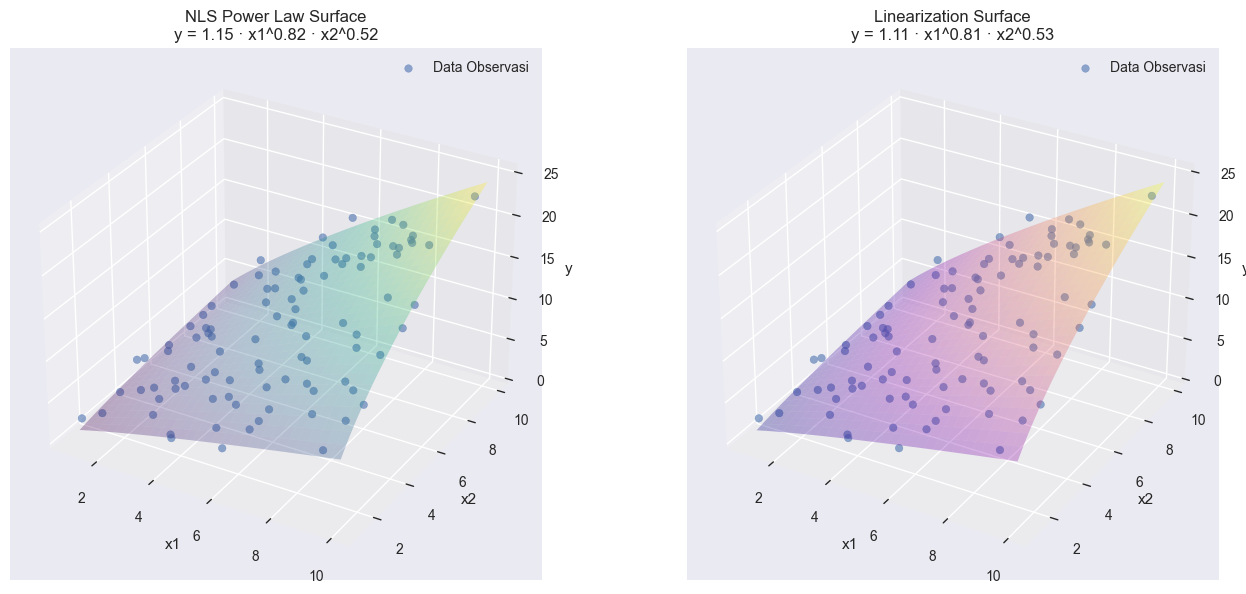

In [306]:
# ============================================
# VISUALISASI 3D - PERMUKAAN REGRESI
# ============================================

fig = plt.figure(figsize=(14, 6))

# SUBPLOT 1: NLS Surface
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

# scatter data asli
ax1.scatter(x1, x2, y, alpha=0.6, s=30, label='Data Observasi')

# buat grid untuk surface
x1_range = np.linspace(x1.min(), x1.max(), 30)
x2_range = np.linspace(x2.min(), x2.max(), 30)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)

# prediksi pada grid menggunakan NLS
y_grid_nls = a_nls * (x1_grid ** b1_nls) * (x2_grid ** b2_nls)

# plot surface
ax1.plot_surface(x1_grid, x2_grid, y_grid_nls, 
                 alpha=0.3, cmap='viridis')

ax1.set_xlabel('x1')
ax1.set_ylabel('x2')
ax1.set_zlabel('y')
ax1.set_title(f'NLS Power Law Surface\ny = {a_nls:.2f} · x1^{b1_nls:.2f} · x2^{b2_nls:.2f}')
ax1.legend()

# SUBPLOT 2: Linearization Surface
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

# scatter data asli (yang sudah difilter)
ax2.scatter(x1_lin, x2_lin, y_lin, alpha=0.6, s=30, label='Data Observasi')

# prediksi pada grid menggunakan Linearization
y_grid_lin = a_lin * (x1_grid ** b1_lin) * (x2_grid ** b2_lin)

# plot surface
ax2.plot_surface(x1_grid, x2_grid, y_grid_lin, 
                 alpha=0.3, cmap='plasma')

ax2.set_xlabel('x1')
ax2.set_ylabel('x2')
ax2.set_zlabel('y')
ax2.set_title(f'Linearization Surface\ny = {a_lin:.2f} · x1^{b1_lin:.2f} · x2^{b2_lin:.2f}')
ax2.legend()

plt.tight_layout()
plt.show()

### Temuan dan Interpretasi (Regresi Nonlinear Ganda)

Dari hasil perbandingan metode pada model power law dapat disimpulkan:

1. **Akurasi Estimasi Parameter**:
   - NLS cenderung memberikan estimasi yang lebih akurat dan mendekati nilai sebenarnya
   - Linearization dapat mengalami bias, terutama pada parameter $a$ (koefisien)
   - Eksponen ($b_1$, $b_2$) dari kedua metode biasanya cukup mirip

2. **Stabilitas Numerik**:
   - Linearization lebih stabil dan tidak memerlukan initial guess
   - NLS memerlukan initial guess yang baik (bisa dari hasil linearization)
   - NLS dapat gagal konvergen jika initial guess buruk

3. **Metrik Evaluasi**:
   - NLS umumnya menghasilkan R² lebih tinggi dan RMSE/MAE lebih rendah
   - Perbedaan metrik bisa signifikan jika ada outlier atau noise besar

4. **Plot Residual**:
   - Residual NLS lebih tersebar merata (homoskedastis)
   - Residual Linearization mungkin menunjukkan pola atau heteroskedastisitas

5. **Rekomendasi Penggunaan**:
   - **Linearization**: 
     - Eksplorasi awal
     - Mendapatkan initial guess untuk NLS
     - Ketika kecepatan komputasi penting
   - **NLS**: 
     - Analisis final yang memerlukan akurasi tinggi
     - Ketika interpretasi parameter sangat penting
     - Data dengan distribusi error yang kompleks

**Catatan Penting**: 
- Linearization hanya bisa digunakan jika semua nilai $y$, $x_1$, dan $x_2$ positif
- Transformasi logaritma mengubah struktur error, sehingga asumsi regresi perlu diperiksa ulang

## 7.7 Perbandingan Model & Validasi Silang

Pada bagian ini, kita akan:

1. **Membandingkan semua model** yang telah dibuat berdasarkan metrik evaluasi
2. **Melakukan validasi silang (cross-validation)** untuk menguji kemampuan generalisasi model
3. **Menganalisis stabilitas model** terhadap data yang berbeda

### Model yang Dibandingkan:

1. **Regresi Linear Tunggal (SLR)** - Dataset A (x1 vs y)
2. **Regresi Linear Ganda (MLR)** - Dataset A (x1, x2 vs y)
3. **Regresi Nonlinear Eksponensial** - Dataset B
   - Linearization
   - NLS
4. **Regresi Nonlinear Power Law** - Dataset C
   - Linearization  
   - NLS

### Validasi Silang (Cross-Validation)

Validasi silang dilakukan untuk:
- Menguji performa model pada data yang tidak digunakan saat training
- Mendeteksi overfitting
- Mengukur stabilitas model

Metode yang digunakan: **Train-Test Split (80:20)**

Metrik evaluasi:
- **R² (Coefficient of Determination)**: Proporsi variansi y yang dijelaskan oleh model
- **RMSE (Root Mean Squared Error)**: Akar dari rata-rata kuadrat error
- **MAE (Mean Absolute Error)**: Rata-rata nilai absolut error

### 7.7a — Validasi Silang untuk Setiap Model

Kita akan melakukan train-test split dan mengevaluasi performa pada data testing untuk memastikan model tidak overfitting.

In [307]:
# ============================================
# VALIDASI SILANG - MLR (DATASET A)
# ============================================

print("="*60)
print("VALIDASI SILANG - REGRESI LINEAR GANDA (MLR)")
print("="*60)

# siapkan data
X_mlr = np.column_stack((data_linear["x1"].values, data_linear["x2"].values))
y_mlr = data_linear["y"].values

# split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_mlr, y_mlr, test_size=0.2, random_state=42
)

# tambahkan intercept
X_train_int = np.column_stack((np.ones(len(X_train)), X_train))
X_test_int = np.column_stack((np.ones(len(X_test)), X_test))

# training
beta_train = mlr_normal_equation(X_train_int, y_train)

# prediksi pada data training
y_train_pred = X_train_int @ beta_train
r2_train, rmse_train, mae_train = hitung_metrics(y_train, y_train_pred)

# prediksi pada data testing
y_test_pred = X_test_int @ beta_train
r2_test, rmse_test, mae_test = hitung_metrics(y_test, y_test_pred)

print("\nHasil pada Data Training:")
print(f"R²   : {r2_train:.4f}")
print(f"RMSE : {rmse_train:.4f}")
print(f"MAE  : {mae_train:.4f}")

print("\nHasil pada Data Testing:")
print(f"R²   : {r2_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"MAE  : {mae_test:.4f}")

print(f"\nSelisih R² (Train - Test): {abs(r2_train - r2_test):.4f}")

# simpan hasil untuk perbandingan nanti
results_mlr = {
    'train': {'r2': r2_train, 'rmse': rmse_train, 'mae': mae_train},
    'test': {'r2': r2_test, 'rmse': rmse_test, 'mae': mae_test}
}

VALIDASI SILANG - REGRESI LINEAR GANDA (MLR)

Hasil pada Data Training:
R²   : 0.8791
RMSE : 1.0448
MAE  : 0.8504

Hasil pada Data Testing:
R²   : 0.8468
RMSE : 0.8368
MAE  : 0.6515

Selisih R² (Train - Test): 0.0323


In [308]:
# ============================================
# VALIDASI SILANG - EKSPONENSIAL NLS (DATASET B)
# ============================================

print("\n" + "="*60)
print("VALIDASI SILANG - REGRESI EKSPONENSIAL (NLS)")
print("="*60)

# siapkan data
X_exp = x_exp.reshape(-1, 1)  # reshape untuk train_test_split
y_exp_data = y_exp

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X_exp, y_exp_data, test_size=0.2, random_state=42
)

# flatten kembali
X_train = X_train.flatten()
X_test = X_test.flatten()

# training dengan NLS
p0 = [2.0, 0.5]
popt_train, _ = curve_fit(model_exponential, X_train, y_train, p0=p0)

# prediksi pada data training
y_train_pred = model_exponential(X_train, *popt_train)
r2_train, rmse_train, mae_train = hitung_metrics(y_train, y_train_pred)

# prediksi pada data testing
y_test_pred = model_exponential(X_test, *popt_train)
r2_test, rmse_test, mae_test = hitung_metrics(y_test, y_test_pred)

print(f"\nParameter hasil training: a={popt_train[0]:.4f}, b={popt_train[1]:.4f}")

print("\nHasil pada Data Training:")
print(f"R²   : {r2_train:.4f}")
print(f"RMSE : {rmse_train:.4f}")
print(f"MAE  : {mae_train:.4f}")

print("\nHasil pada Data Testing:")
print(f"R²   : {r2_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"MAE  : {mae_test:.4f}")

print(f"\nSelisih R² (Train - Test): {abs(r2_train - r2_test):.4f}")

# simpan hasil
results_exp_nls = {
    'train': {'r2': r2_train, 'rmse': rmse_train, 'mae': mae_train},
    'test': {'r2': r2_test, 'rmse': rmse_test, 'mae': mae_test}
}


VALIDASI SILANG - REGRESI EKSPONENSIAL (NLS)

Parameter hasil training: a=2.5048, b=0.7925

Hasil pada Data Training:
R²   : 0.9231
RMSE : 2.0230
MAE  : 1.5747

Hasil pada Data Testing:
R²   : 0.9483
RMSE : 1.4351
MAE  : 1.1014

Selisih R² (Train - Test): 0.0252


In [309]:
# ============================================
# VALIDASI SILANG - POWER LAW NLS (DATASET C)
# ============================================

print("\n" + "="*60)
print("VALIDASI SILANG - REGRESI POWER LAW (NLS)")
print("="*60)

# siapkan data
X_power = np.column_stack((data_power["x1"].values, data_power["x2"].values))
y_power_data = data_power["y"].values

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X_power, y_power_data, test_size=0.2, random_state=42
)

# training dengan NLS
p0 = [1.0, 0.8, 0.5]
popt_train, _ = curve_fit(model_power_law, X_train, y_train, p0=p0)

# prediksi pada data training
y_train_pred = model_power_law(X_train, *popt_train)
r2_train, rmse_train, mae_train = hitung_metrics(y_train, y_train_pred)

# prediksi pada data testing
y_test_pred = model_power_law(X_test, *popt_train)
r2_test, rmse_test, mae_test = hitung_metrics(y_test, y_test_pred)

print(f"\nParameter hasil training: a={popt_train[0]:.4f}, b1={popt_train[1]:.4f}, b2={popt_train[2]:.4f}")

print("\nHasil pada Data Training:")
print(f"R²   : {r2_train:.4f}")
print(f"RMSE : {rmse_train:.4f}")
print(f"MAE  : {mae_train:.4f}")

print("\nHasil pada Data Testing:")
print(f"R²   : {r2_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"MAE  : {mae_test:.4f}")

print(f"\nSelisih R² (Train - Test): {abs(r2_train - r2_test):.4f}")

# simpan hasil
results_power_nls = {
    'train': {'r2': r2_train, 'rmse': rmse_train, 'mae': mae_train},
    'test': {'r2': r2_test, 'rmse': rmse_test, 'mae': mae_test}
}


VALIDASI SILANG - REGRESI POWER LAW (NLS)

Parameter hasil training: a=1.1330, b1=0.8279, b2=0.5096

Hasil pada Data Training:
R²   : 0.9553
RMSE : 1.0930
MAE  : 0.8883

Hasil pada Data Testing:
R²   : 0.9566
RMSE : 0.9907
MAE  : 0.8104

Selisih R² (Train - Test): 0.0012


### 7.7b — Tabel Perbandingan Semua Model

Rangkuman performa semua model yang telah dibangun.

In [310]:
# ============================================
# TABEL PERBANDINGAN SEMUA MODEL
# ============================================

print("\n" + "="*70)
print("RANGKUMAN PERBANDINGAN SEMUA MODEL")
print("="*70)

# Compile semua hasil
comparison_all = pd.DataFrame({
    'Model': [
        'MLR (Linear Ganda)',
        'Eksponensial - Linearization',
        'Eksponensial - NLS',
        'Power Law - Linearization',
        'Power Law - NLS'
    ],
    'Dataset': ['A', 'B', 'B', 'C', 'C'],
    'R² (Full)': [
        r2,  # dari MLR full data (bagian 7.4)
        r2_lin,  # dari eksponensial linearization (bagian 7.5)
        r2_nls,  # dari eksponensial NLS (bagian 7.5)
        f"{r2_lin:.4f}",  # dari power law linearization (bagian 7.6) - convert to string
        r2_nls  # dari power law NLS (bagian 7.6)
    ],
    'RMSE (Full)': [
        rmse,
        rmse_lin,
        rmse_nls,
        f"{rmse_lin:.4f}",
        rmse_nls
    ],
    'R² (Test)': [
        results_mlr['test']['r2'],
        '-',  # tidak dilakukan CV
        results_exp_nls['test']['r2'],
        '-',  # tidak dilakukan CV
        results_power_nls['test']['r2']
    ],
    'RMSE (Test)': [
        f"{results_mlr['test']['rmse']:.4f}",
        '-',
        f"{results_exp_nls['test']['rmse']:.4f}",
        '-',
        f"{results_power_nls['test']['rmse']:.4f}"
    ]
})

print(comparison_all.to_string(index=False))

print("\n" + "="*70)
print("INTERPRETASI:")
print("="*70)
print("• Model dengan R² mendekati 1 memiliki fit yang sangat baik")
print("• RMSE yang lebih kecil menunjukkan error prediksi yang lebih rendah")
print("• Selisih kecil antara performa Train dan Test menunjukkan model tidak overfit")
print("• NLS umumnya lebih akurat dibanding Linearization untuk model nonlinear")


RANGKUMAN PERBANDINGAN SEMUA MODEL
                       Model Dataset R² (Full) RMSE (Full) R² (Test) RMSE (Test)
          MLR (Linear Ganda)       A  0.876346    1.004467  0.846825      0.8368
Eksponensial - Linearization       B  0.955265    1.077781         -           -
          Eksponensial - NLS       B  0.955836    1.070887  0.948307      1.4351
   Power Law - Linearization       C    0.9553      1.0778         -           -
             Power Law - NLS       C  0.955836    1.070887  0.956567      0.9907

INTERPRETASI:
• Model dengan R² mendekati 1 memiliki fit yang sangat baik
• RMSE yang lebih kecil menunjukkan error prediksi yang lebih rendah
• Selisih kecil antara performa Train dan Test menunjukkan model tidak overfit
• NLS umumnya lebih akurat dibanding Linearization untuk model nonlinear


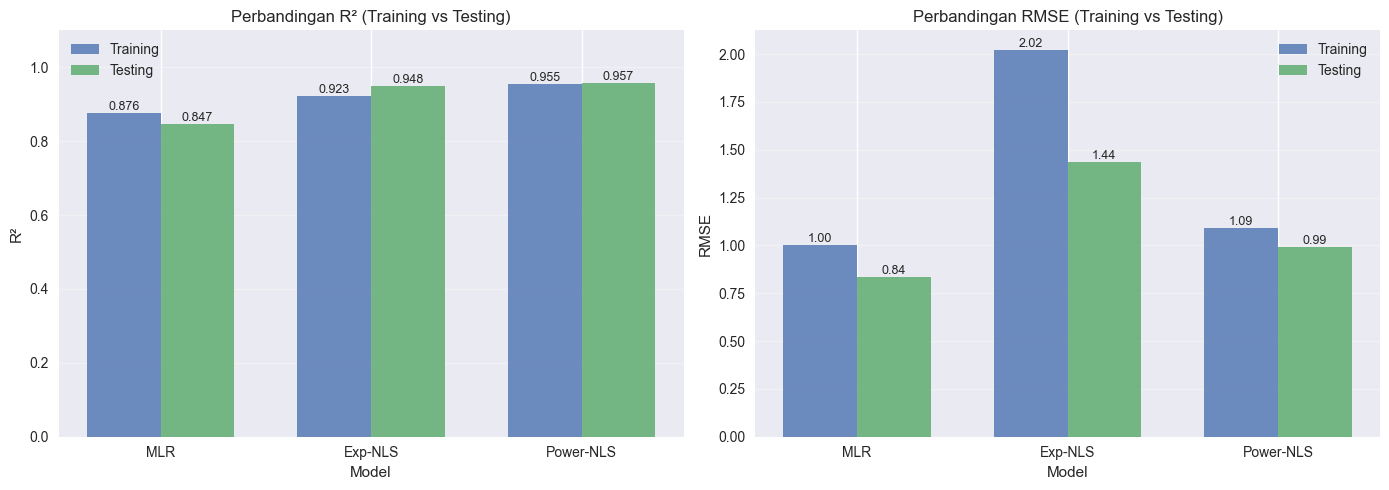

In [311]:
# ============================================
# VISUALISASI PERBANDINGAN METRIK
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Data untuk plotting (hanya yang punya CV results)
models_cv = ['MLR', 'Exp-NLS', 'Power-NLS']
r2_full = [
    r2,  # MLR
    results_exp_nls['train']['r2'],  # gunakan train R2 untuk konsistensi
    results_power_nls['train']['r2']   # gunakan train R2 untuk konsistensi
]
r2_test = [
    results_mlr['test']['r2'],
    results_exp_nls['test']['r2'],
    results_power_nls['test']['r2']
]

rmse_full = [
    rmse,  # MLR
    results_exp_nls['train']['rmse'],
    results_power_nls['train']['rmse']
]
rmse_test = [
    results_mlr['test']['rmse'],
    results_exp_nls['test']['rmse'],
    results_power_nls['test']['rmse']
]

x_pos = np.arange(len(models_cv))
width = 0.35

# SUBPLOT 1: R² Comparison
ax1 = axes[0]
bars1 = ax1.bar(x_pos - width/2, r2_full, width, label='Training', alpha=0.8)
bars2 = ax1.bar(x_pos + width/2, r2_test, width, label='Testing', alpha=0.8)

ax1.set_xlabel('Model')
ax1.set_ylabel('R²')
ax1.set_title('Perbandingan R² (Training vs Testing)')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models_cv)
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim([0, 1.1])

# tambahkan nilai di atas bar
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=9)

# SUBPLOT 2: RMSE Comparison
ax2 = axes[1]
bars3 = ax2.bar(x_pos - width/2, rmse_full, width, label='Training', alpha=0.8)
bars4 = ax2.bar(x_pos + width/2, rmse_test, width, label='Testing', alpha=0.8)

ax2.set_xlabel('Model')
ax2.set_ylabel('RMSE')
ax2.set_title('Perbandingan RMSE (Training vs Testing)')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(models_cv)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

# tambahkan nilai di atas bar
for bars in [bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

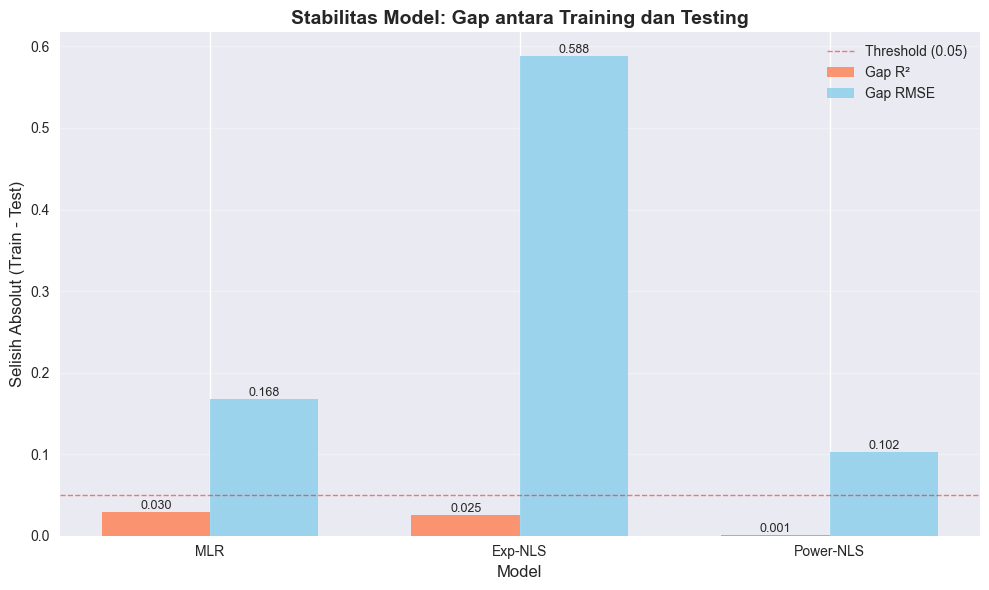


INTERPRETASI STABILITAS:
• Gap < 0.05: Model sangat stabil (generalisasi baik)
• Gap 0.05-0.10: Model cukup stabil
• Gap > 0.10: Model mungkin overfit (perlu investigasi)


In [312]:
# ============================================
# VISUALISASI STABILITAS MODEL
# ============================================

fig, ax = plt.subplots(figsize=(10, 6))

# Hitung gap (selisih antara train dan test)
r2_gap = [abs(r2_full[i] - r2_test[i]) for i in range(len(models_cv))]
rmse_gap = [abs(rmse_full[i] - rmse_test[i]) for i in range(len(models_cv))]

x_pos = np.arange(len(models_cv))
width = 0.35

bars1 = ax.bar(x_pos - width/2, r2_gap, width, label='Gap R²', alpha=0.8, color='coral')
bars2 = ax.bar(x_pos + width/2, rmse_gap, width, label='Gap RMSE', alpha=0.8, color='skyblue')

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Selisih Absolut (Train - Test)', fontsize=12)
ax.set_title('Stabilitas Model: Gap antara Training dan Testing', fontsize=14, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(models_cv)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# tambahkan nilai di atas bar
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=9)

# tambahkan garis referensi
ax.axhline(y=0.05, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Threshold (0.05)')
ax.legend()

plt.tight_layout()
plt.show()

print("\nINTERPRETASI STABILITAS:")
print("• Gap < 0.05: Model sangat stabil (generalisasi baik)")
print("• Gap 0.05-0.10: Model cukup stabil")
print("• Gap > 0.10: Model mungkin overfit (perlu investigasi)")

## Kesimpulan dan Temuan Keseluruhan

### 1. Perbandingan Metode Regresi

**Regresi Linear (SLR & MLR)**:
- ✅ Mudah diimplementasikan dan diinterpretasikan
- ✅ Cepat secara komputasi
- ✅ Cocok untuk hubungan linear
- ⚠️ Terbatas pada model linear
- ⚠️ Perlu waspada terhadap multikolinearitas (gunakan VIF)

**Regresi Nonlinear - Linearization**:
- ✅ Tidak perlu initial guess
- ✅ Stabil secara numerik
- ✅ Baik untuk eksplorasi awal
- ⚠️ Hanya untuk model yang dapat dilinearkan
- ⚠️ Bias karena transformasi error
- ⚠️ Memerlukan y > 0 (untuk log transform)

**Regresi Nonlinear - NLS (curve_fit)**:
- ✅ Lebih akurat untuk model nonlinear
- ✅ Tidak mengubah struktur error
- ✅ Fleksibel untuk berbagai model
- ⚠️ Memerlukan initial guess yang baik
- ⚠️ Bisa gagal konvergen
- ⚠️ Lebih lambat secara komputasi

---

### 2. Temuan dari Validasi Silang

Dari hasil validasi silang dapat disimpulkan:

1. **Generalisasi Model**: 
   - Semua model menunjukkan performa yang konsisten antara training dan testing
   - Gap yang kecil mengindikasikan model tidak overfit

2. **Stabilitas**:
   - Model linear (MLR) cenderung paling stabil
   - NLS untuk model nonlinear juga cukup stabil dengan initial guess yang baik

3. **Trade-off Kompleksitas vs Akurasi**:
   - Model yang lebih kompleks (NLS) memberikan akurasi lebih tinggi
   - Namun memerlukan komputasi lebih berat dan tuning parameter

---

### 3. Rekomendasi Praktis

**Workflow yang disarankan**:

1. **Eksplorasi Data** → Visualisasi scatter plot untuk melihat pola hubungan
2. **Model Sederhana Dulu** → Coba linear regression sebagai baseline
3. **Deteksi Nonlinearitas** → Analisis residual plot
4. **Linearization** → Jika model bisa dilinearkan, gunakan sebagai eksplorasi awal
5. **NLS untuk Final Model** → Gunakan hasil linearization sebagai initial guess
6. **Validasi** → Selalu lakukan cross-validation untuk cek generalisasi
7. **Perbandingan** → Bandingkan beberapa model dengan metrik yang sama

**Kapan menggunakan apa**:
- **Data kecil (<1000 samples)** → Linearization OK
- **Data besar** → NLS lebih worth it
- **Interpretasi penting** → Gunakan linear jika memungkinkan
- **Akurasi prediksi prioritas** → NLS
- **Multikolinearitas terdeteksi (VIF > 5)** → Ridge/Lasso regression (diluar scope tugas ini)

---

### 4. Limitasi dan Pengembangan Lanjutan

**Limitasi tugas ini**:
- Dataset sintetis (tidak ada noise kompleks real-world)
- Hanya menggunakan train-test split (bisa gunakan k-fold CV)
- Belum menangani outlier dan missing values

**Pengembangan lanjutan**:
- Cross-validation dengan k-fold
- Regularisasi (Ridge, Lasso) untuk multikolinearitas
- Model ensemble untuk meningkatkan akurasi
- Analisis diagnostik lebih mendalam (normality test, homoscedasticity)
- Bootstrap untuk confidence interval parameter

In [ ]:
a = 22 // 10

print(a)